# TP3 – Variabilité de `(x+y)+z == x+(y+z)` : analyse des résultats

Ce notebook **lit** les CSV produits par GitHub Actions (`results/results_ci.csv`) et par `causal.py` (`results/causal.csv`). Il ne produit aucune donnée.

**Reproduire** : `jupyter lab`, puis *Restart Kernel and Run All Cells* (le notebook se lance depuis le dossier `tp3/`).

**Déclaration d'usage de l'IA** : outil utilisé (Claude, Gemini), usage détaillé dans le `README.md`.

## 0. Chargement des données

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

df = pd.read_csv("results/results_ci.csv")
df["Optimization"] = df["Optimization"].fillna("none")
df["python_v"] = df["python"].astype(str).str.extract(r"^(\d+\.\d+)")[0]
df["gcc_v"] = df["gcc"].astype(str).str.extract(r"^(\d+)")[0]
# version qui compte vraiment : gcc pour un programme C, Python pour un programme Python
df["lang_version"] = np.where(df["Language"] == "LangC", "gcc " + df["gcc_v"].astype(str),
                              "python " + df["python_v"].astype(str))
print(len(df), "exécutions,", df["config_id"].nunique(), "configurations,",
      df.groupby(["python_v", "gcc_v"]).ngroups, "environnements")
df.head(3)

2060 exécutions, 103 configurations, 4 environnements


,config_id,origin_of_config,Language,NumType,Generator,Interval,Repetitions,Seed,Property,Optimization,run,seed_used,repetitions_n,low,high,percentage,machine,os,python,gcc,python_v,gcc_v,lang_version
0,p1,anchor,LangC,Float32,GenRandC,Int_0_1,Rep1000000,Seed42,AssocAdd,O2,1,42,1000000,0.0,1.0,74.6318,x86_64,Linux-7.0.0-1017-azure-x86_64-with-glibc2.39,3.10.22,12.4.0,3.10,12,gcc 12
1,p1,anchor,LangC,Float32,GenRandC,Int_0_1,Rep1000000,Seed42,AssocAdd,O2,2,42,1000000,0.0,1.0,74.6318,x86_64,Linux-7.0.0-1017-azure-x86_64-with-glibc2.39,3.10.22,12.4.0,3.10,12,gcc 12
2,p1,anchor,LangC,Float32,GenRandC,Int_0_1,Rep1000000,Seed42,AssocAdd,O2,3,42,1000000,0.0,1.0,74.6318,x86_64,Linux-7.0.0-1017-azure-x86_64-with-glibc2.39,3.10.22,12.4.0,3.10,12,gcc 12


## 1. Les facteurs de variabilité

Facteurs du modèle UVL (`fm/experiment.uvl`) : langage, type des nombres, générateur, intervalle, répétitions, graine, propriété testée, optimisation de compilation. Facteurs d'environnement ajoutés par la matrice GitHub Actions : version de gcc (12, 14) et de Python (3.10, 3.14).

L'architecture CPU (x86_64, ARM) a été identifiée mais **n'a pas été testée** (choix de retirer ARM) : on ne peut rien en conclure.

## 2. À quel point chaque facteur change-t-il la réponse ?

In [2]:
print(df["percentage"].describe().round(2))
factors = ["Language", "NumType", "Generator", "Interval", "Repetitions", "Property", "Optimization", "lang_version"]
rows = []
for f in factors:
    m = df.groupby(f)["percentage"].mean()
    rows.append((f, round(m.max() - m.min(), 2), m.idxmax(), m.idxmin()))
effects = pd.DataFrame(rows, columns=["facteur", "écart entre moyennes (points)", "valeur la plus haute", "valeur la plus basse"])
effects.sort_values("écart entre moyennes (points)", ascending=False).reset_index(drop=True)

count    2060.00
mean       80.65
std        13.87
min        53.00
25%        65.15
50%        84.68
75%        93.00
max       100.00
Name: percentage, dtype: float64


,facteur,écart entre moyennes (points),valeur la plus haute,valeur la plus basse
0,Optimization,21.05,O2FastMath,O2
1,Property,16.08,AssocAdd,AssocMul
2,Repetitions,7.63,Rep100000,Rep10000000
3,Interval,5.54,Int_m1e15_1e15,Int_m1000_1000
4,Generator,5.46,GenRandC,GenPyNative
5,lang_version,4.68,gcc 14,python 3.14
6,Language,4.61,LangC,LangPython
7,NumType,0.95,Float32,Float64


*Lecture* : l'écart entre moyennes est un indicateur grossier. L'échantillon est aléatoire et déséquilibré, et les facteurs interagissent (par exemple type × intervalle, vu en 3.2). Un facteur peut donc paraître fort ou faible à cause des autres valeurs avec lesquelles il est combiné. L'arbre de décision plus bas tient compte de ces combinaisons.

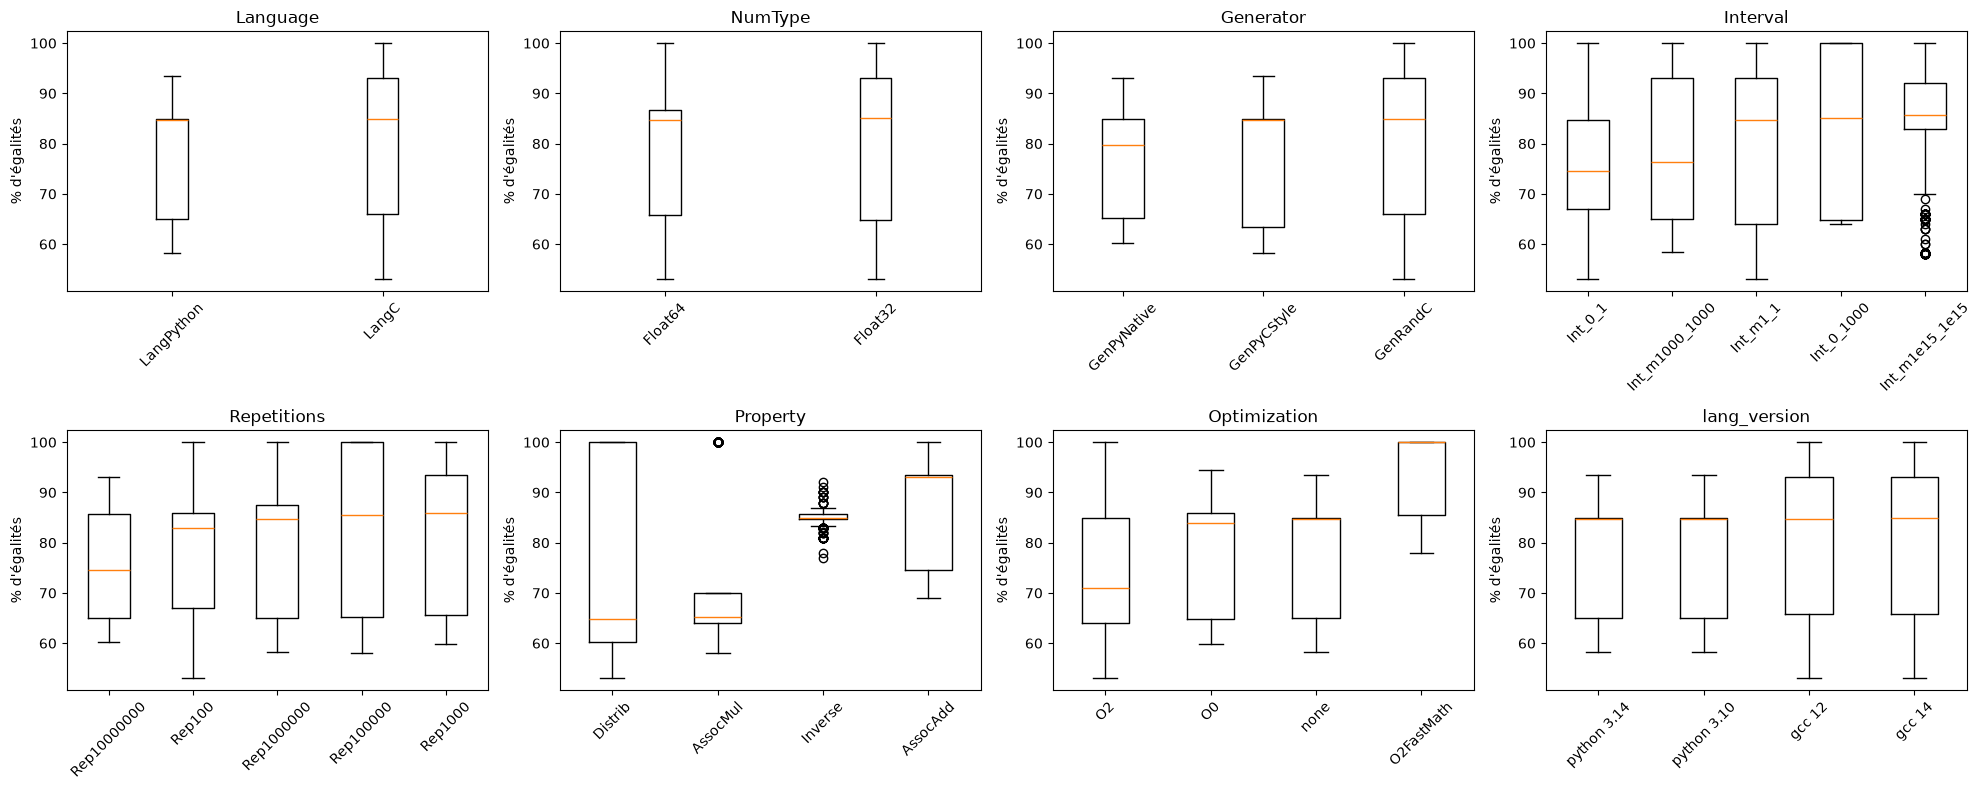

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, f in zip(axes.ravel(), factors):
    order = df.groupby(f)["percentage"].median().sort_values().index
    ax.boxplot([df.loc[df[f] == v, "percentage"] for v in order])
    ax.set_xticklabels(order); ax.set_title(f); ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("% d'égalités")
plt.tight_layout(); plt.show()

## 3. Arbre de décision (apprentissage interprétable)

In [4]:
cols = ["Language", "NumType", "Generator", "Interval", "Repetitions", "Property", "Optimization", "lang_version"]
X = pd.get_dummies(df[cols].astype(str))
y = df["percentage"]
tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=0).fit(X, y)
print("R² de l'arbre (profondeur 4) :", round(tree.score(X, y), 3))
print(export_text(tree, feature_names=list(X.columns)))
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
imp[imp > 0].round(3)

R² de l'arbre (profondeur 4) : 0.896
|--- Optimization_O2FastMath <= 0.50
|   |--- Property_Distrib <= 0.50
|   |   |--- Property_AssocMul <= 0.50
|   |   |   |--- Interval_Int_0_1 <= 0.50
|   |   |   |   |--- value: [88.19]
|   |   |   |--- Interval_Int_0_1 >  0.50
|   |   |   |   |--- value: [79.05]
|   |   |--- Property_AssocMul >  0.50
|   |   |   |--- Repetitions_Rep1000000 <= 0.50
|   |   |   |   |--- value: [64.32]
|   |   |   |--- Repetitions_Rep1000000 >  0.50
|   |   |   |   |--- value: [73.77]
|   |--- Property_Distrib >  0.50
|   |   |--- Interval_Int_0_1 <= 0.50
|   |   |   |--- Interval_Int_0_1000 <= 0.50
|   |   |   |   |--- value: [59.98]
|   |   |   |--- Interval_Int_0_1000 >  0.50
|   |   |   |   |--- value: [64.72]
|   |   |--- Interval_Int_0_1 >  0.50
|   |   |   |--- Generator_GenPyNative <= 0.50
|   |   |   |   |--- value: [64.55]
|   |   |   |--- Generator_GenPyNative >  0.50
|   |   |   |   |--- value: [75.00]
|--- Optimization_O2FastMath >  0.50
|   |--- Proper

Optimization_O2FastMath    0.364
Property_AssocMul          0.264
Property_Distrib           0.229
Property_Inverse           0.072
Interval_Int_0_1           0.047
Repetitions_Rep1000000     0.016
Generator_GenPyNative      0.005
Interval_Int_0_1000        0.003
Interval_Int_m1_1          0.000
Repetitions_Rep1000        0.000
Repetitions_Rep100         0.000
dtype: float64

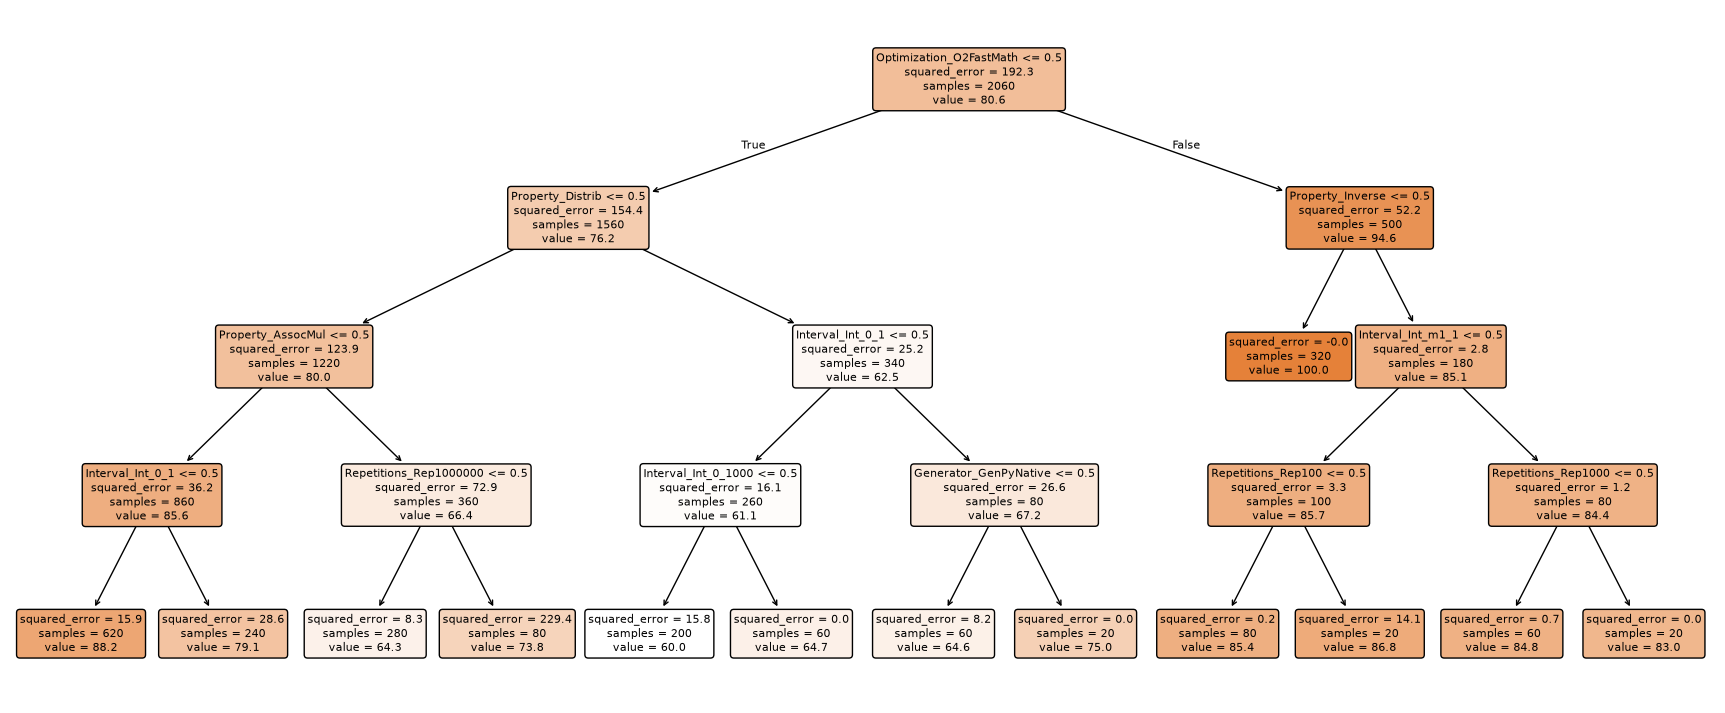

In [5]:
plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=list(X.columns), filled=True, rounded=True, fontsize=8, precision=1)
plt.show()

*Lecture* : une corrélation n'est pas une causalité. L'arbre dit quels facteurs **séparent** les résultats dans cet échantillon, pas pourquoi. La section 6 teste les causes en ne changeant qu'un seul facteur.

## 4. Stabilité : mêmes arguments, même réponse ?

In [6]:
# (a) Dans un même environnement : exécutions répétées de la même configuration
grp = df.groupby(["config_id", "python", "gcc"])["percentage"]
within = grp.agg(["std", "nunique"]).reset_index()
within = within.merge(df[["config_id", "Seed", "Repetitions"]].drop_duplicates(), on="config_id")
fixed = within[within["Seed"] != "SeedNotFixed"]
free = within[within["Seed"] == "SeedNotFixed"]
print("Graine fixée : configurations dont les exécutions répétées donnent des résultats différents :",
      int((fixed["nunique"] > 1).sum()), "sur", len(fixed))
print("Graine non fixée : écart-type moyen entre exécutions (points) :", round(free["std"].mean(), 3))
order = ["Rep100", "Rep1000", "Rep100000", "Rep1000000", "Rep10000000"]
(free.groupby("Repetitions")["std"].mean().reindex([o for o in order if o in set(free["Repetitions"])])
 .rename("écart-type entre exécutions (points)").round(3))

Graine fixée : configurations dont les exécutions répétées donnent des résultats différents : 0 sur 320
Graine non fixée : écart-type moyen entre exécutions (points) : 0.927


Repetitions
Rep100         3.460
Rep1000        1.228
Rep100000      0.018
Rep1000000     0.034
Rep10000000    0.012
Name: écart-type entre exécutions (points), dtype: float64

In [7]:
# (b) Entre environnements : même configuration à graine fixée, versions différentes
fx = df[df["Seed"] != "SeedNotFixed"]
per_env = fx.groupby(["config_id", "Language", "lang_version"])["percentage"].agg(["first", "nunique"]).reset_index()
print("Cas où une même version donne plusieurs réponses (doit être 0) :", int((per_env["nunique"] > 1).sum()))
wide = per_env.pivot_table(index=["config_id", "Language"], columns="lang_version", values="first")
wide["écart max"] = wide.max(axis=1) - wide.min(axis=1)
print("Configurations à graine fixée dont la réponse change avec la version :",
      int((wide["écart max"] > 0).sum()), "sur", len(wide))
wide.groupby("Language")["écart max"].describe().round(4)

Cas où une même version donne plusieurs réponses (doit être 0) : 0
Configurations à graine fixée dont la réponse change avec la version : 0 sur 80


,count,mean,std,min,25%,50%,75%,max
Language,,,,,,,,
LangC,63.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
LangPython,17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# (c) Même commit, deuxième exécution du workflow ? (si results_ci_attempt2.csv existe)
a1, a2 = Path("results/results_ci_attempt1.csv"), Path("results/results_ci_attempt2.csv")
if a1.exists() and a2.exists():
    r1, r2 = pd.read_csv(a1), pd.read_csv(a2)
    key = ["config_id", "run", "python", "gcc"]
    m = r1.merge(r2, on=key, suffixes=("_1", "_2"))
    m["Seed"] = m["Seed_1"]
    same = (m["percentage_1"] == m["percentage_2"])
    print("Graine fixée : réponses identiques entre les deux exécutions :",
          round(same[m["Seed"] != "SeedNotFixed"].mean() * 100, 1), "%")
    print("Graine non fixée : réponses identiques :",
          round(same[m["Seed"] == "SeedNotFixed"].mean() * 100, 1), "%")
else:
    print("Pas de deuxième exécution du workflow dans le dépôt (results_ci_attempt2.csv).")

Pas de deuxième exécution du workflow dans le dépôt (results_ci_attempt2.csv).


## 5. Effet de l'optimisation de compilation

In [9]:
c = df[df["Language"] == "LangC"]
print(c.groupby("Optimization")["percentage"].agg(["count", "mean", "std"]).round(2))
fm = c[c["Optimization"] == "O2FastMath"]["percentage"]
print("Part des exécutions -ffast-math à exactement 100 % :", round((fm == 100).mean() * 100, 1), "%")

              count   mean    std
Optimization                     
O0              540  78.08  12.24
O2              560  73.58  12.58
O2FastMath      500  94.63   7.23
Part des exécutions -ffast-math à exactement 100 % : 64.0 %


## 6. Causalité : une expérience, un seul facteur qui change

Les tableaux ci-dessus montrent des corrélations. Pour établir une cause, `causal.py` (versionné, lancé à part) compare des programmes **identiques sauf un facteur**, avec 5 graines chacun. Résultats lus dans `results/causal.csv`.

In [10]:
cz = pd.read_csv("results/causal.csv")
t = cz.groupby(["experiment", "variant"])["percentage"].agg(["count", "mean", "std"]).round(3)
t

count     mean    std
experiment                      variant                                                     
compiler flag (C, float, [0,1]) -O2                                        5   74.614  0.057
                                -O2 -ffast-math                            5  100.000  0.000
generator (Python, [0,1])       entier/(2^31-1) comme rand()/RAND_MAX      5   74.560  0.074
                                random() natif                             5   82.798  0.052
interval (C, float)             [-1,1]                                     5   93.051  0.011
                                [0,1]                                      5   74.614  0.057
type (C, [-1e15,1e15])          double                                     5   93.016  0.011
                                float                                      5   92.077  0.006

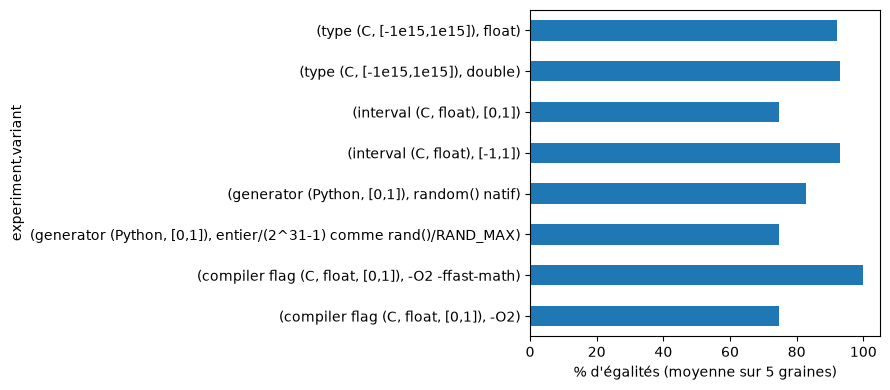

In [11]:
summ = cz.groupby(["experiment", "variant"])["percentage"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
cz.groupby(["experiment", "variant"])["percentage"].mean().plot.barh(ax=ax)
ax.set_xlabel("% d'égalités (moyenne sur 5 graines)"); plt.tight_layout(); plt.show()

## 7. Conclusions

*Ces constats reposent sur les mesures de ce dépôt (sections 2 à 6). Vérifier les chiffres dans les tableaux ci-dessus après chaque ré-exécution.*

**Facteurs qui changent la réponse (mesurés par expérience contrôlée, 1 000 000 de répétitions, 5 graines)**
- `-ffast-math` : ce seul flag fait passer le test à 100 %. Il autorise gcc à réassocier les additions, donc la comparaison devient triviale. Cause démontrée (un seul facteur change).
- Le signe des nombres tirés : intervalle [0, 1] contre [-1, 1] (≈ 74,6 % contre ≈ 93 % pour `float`). L'échelle (1, 1000) compte peu.
- La manière de fabriquer le nombre aléatoire : `random()` de Python (≈ 82,8 %) contre un entier divisé par 2³¹-1, comme `rand()/RAND_MAX` (≈ 74,5 %), sur [0, 1]. Le mécanisme (structure binaire des valeurs) reste une hypothèse.
- La propriété testée : sur [0, 1], `x*(1/x)==1` ≈ 84,7 %, associativité de `+` ≈ 74,6 %, associativité de `*` ≈ 65,1 %, distributivité ≈ 64,7 %.
- Le type (`float`/`double`) : effet nul sur [0, 1], [-1, 1] et [-1000, 1000], mais ≈ 0,9 point sur [-1e15, 1e15]. L'effet dépend donc de l'intervalle (interaction).

**Facteurs sans effet constaté** : `-O0` contre `-O2` (même résultat), ordre des tirages (x, y, z contre y, x, z). Les versions de gcc et de Python : voir la section 4(b) pour la réponse sur ces données.

**Non testé** : architecture CPU (x86_64/ARM), autres compilateurs que gcc, autres bibliothèques.

**Recommandations pour un résultat stable**
1. Ne jamais compiler avec `-ffast-math` pour cette question.
2. Fixer la graine et l'écrire dans le résultat ; sinon, indiquer l'écart entre exécutions.
3. Utiliser au moins 100 000 à 1 000 000 de répétitions (section 4(a) : l'écart-type entre exécutions diminue avec le nombre de répétitions).
4. Documenter l'intervalle (en particulier le signe), le générateur et le type : ce sont eux qui font la réponse.
5. Définir « même résultat » : identique au chiffre près pour une graine fixée, compatible dans la marge statistique (≈ ±0,05 point à 10⁶ répétitions) sinon.

## 8. Explication des réponses des labs #1 et #2

- **Associativité, lab #1 (C, 746552)** : ce nombre est un compte sur 1 000 000 d'essais, soit 74,6552 %. Le programme utilisait `float`, `rand()/RAND_MAX`, `srand(42)` et l'intervalle [0, 1]. Ce sont exactement les conditions qui donnent ≈ 74,6 %.
- **Associativité, lab #2 (Gemini, Python, 93,04 %)** : intervalle [-1e15, 1e15], donc des nombres de signes opposés, qui donnent ≈ 93 %. Le type 64 bits donne environ 1 point de plus qu'en 32 bits sur cet intervalle.
- **Banking, lab #1 (C, -4,39e48)** : la formule est correcte, mais `exp(1.0)` en `double` porte une erreur d'environ 1e-16, que les 50 multiplications amplifient par 50! ≈ 3e64. Le résultat est du bruit d'arrondi.
- **Banking, lab #2** : la première tentative de Gemini avait le même défaut (`Decimal(str(math.e))`, e tronqué). La version corrigée calcule e avec 100 chiffres (`Decimal(1).exp()`) et donne ≈ 0,0199921658 €.